In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

In [2]:
FILE_PATH = "most_used_beauty_cosmetics_products_extended.csv"

if not os.path.exists(FILE_PATH):
    raise FileNotFoundError(
        f"Dataset '{FILE_PATH}' was not found. "
        "Update FILE_PATH with your actual CSV filename."
    )


In [3]:
df = pd.read_csv(FILE_PATH)

In [4]:
print("=" * 60)
print("BEAUTY & WELLNESS DATASET")
print("=" * 60)
print("\nFirst five rows:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

BEAUTY & WELLNESS DATASET

First five rows:
       Product_Name              Brand        Category Usage_Frequency  \
0   Ultra Face Mask     Drunk Elephant           Blush          Weekly   
1    Ultra Lipstick      Laura Mercier  Makeup Remover      Occasional   
2       Ultra Serum     Natasha Denona     Highlighter           Daily   
3      Divine Serum        Ilia Beauty       Face Mask      Occasional   
4  Super Foundation  Charlotte Tilbury     Highlighter      Occasional   

   Price_USD  Rating  Number_of_Reviews Product_Size  Skin_Type Gender_Target  \
0      67.85     1.4                686         30ml  Sensitive        Female   
1     116.43     4.2               5483        250ml        Dry        Unisex   
2      90.84     1.6               5039        100ml  Sensitive          Male   
3      55.17     3.2               6202        250ml     Normal          Male   
4     140.56     1.7                297        100ml       Oily        Female   

  Packaging_Type Main_In

In [5]:
print("\nMissing values:")
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})
print(missing.sort_values("Missing_Percentage", ascending=False))
print("\nDuplicate rows:", df.duplicated().sum())
print("\nNumerical summary:")
print(df.describe(include=[np.number]).T)
print("\nCategorical summary:")
print(df.describe(include=["object", "category"]).T)
os.makedirs("outputs", exist_ok=True)
missing.to_csv("outputs/missing_values_report.csv")
df = df.drop_duplicates().copy()


Missing values:
                   Missing_Count  Missing_Percentage
Product_Name                   0                 0.0
Brand                          0                 0.0
Category                       0                 0.0
Usage_Frequency                0                 0.0
Price_USD                      0                 0.0
Rating                         0                 0.0
Number_of_Reviews              0                 0.0
Product_Size                   0                 0.0
Skin_Type                      0                 0.0
Gender_Target                  0                 0.0
Packaging_Type                 0                 0.0
Main_Ingredient                0                 0.0
Cruelty_Free                   0                 0.0
Country_of_Origin              0                 0.0

Duplicate rows: 0

Numerical summary:
                     count         mean          std   min      25%      50%  \
Price_USD          15000.0    80.134108    40.402983  10.0    45.48  

In [6]:
numeric_columns = df.select_dtypes(include=np.number).columns
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns 
for col in numeric_columns:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())
for col in categorical_columns:
    if df[col].isnull().any():
        mode_values = df[col].mode()
        if not mode_values.empty:
            df[col] = df[col].fillna(mode_values.iloc[0])
print("\nMissing values after basic imputation:")
print(df.isnull().sum())


Missing values after basic imputation:
Product_Name         0
Brand                0
Category             0
Usage_Frequency      0
Price_USD            0
Rating               0
Number_of_Reviews    0
Product_Size         0
Skin_Type            0
Gender_Target        0
Packaging_Type       0
Main_Ingredient      0
Cruelty_Free         0
Country_of_Origin    0
dtype: int64


In [7]:
numeric_columns = df.select_dtypes(include=np.number).columns

print("\nUpdated numerical summary:")
print(df[numeric_columns].describe().T)



Updated numerical summary:
                     count         mean          std   min      25%      50%  \
Price_USD          15000.0    80.134108    40.402983  10.0    45.48    80.04   
Rating             15000.0     3.002327     1.168029   1.0     2.00     3.00   
Number_of_Reviews  15000.0  5014.231333  2855.665464  52.0  2562.00  5002.00   

                       75%       max  
Price_USD           114.76    149.99  
Rating                4.00      5.00  
Number_of_Reviews  7497.00  10000.00  


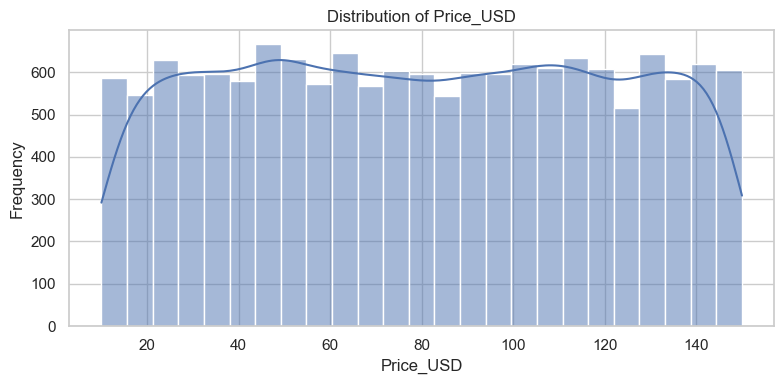

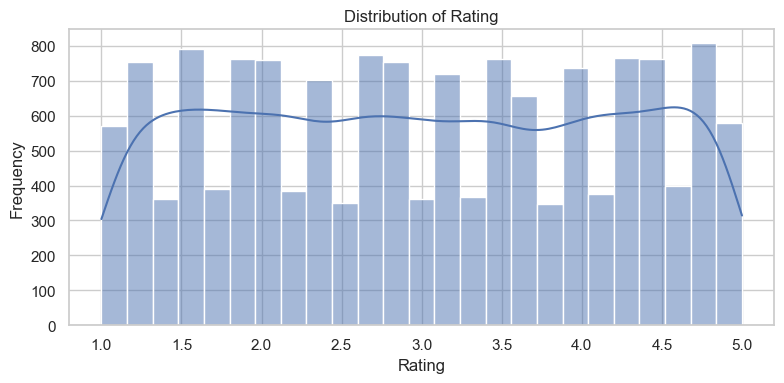

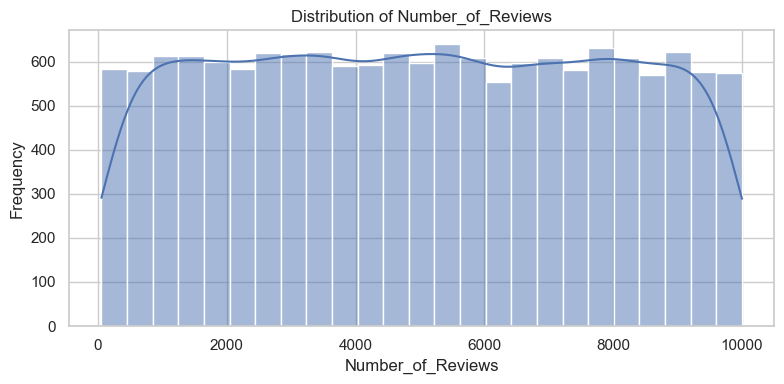

In [8]:
for col in numeric_columns[:10]:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[col].dropna(), kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


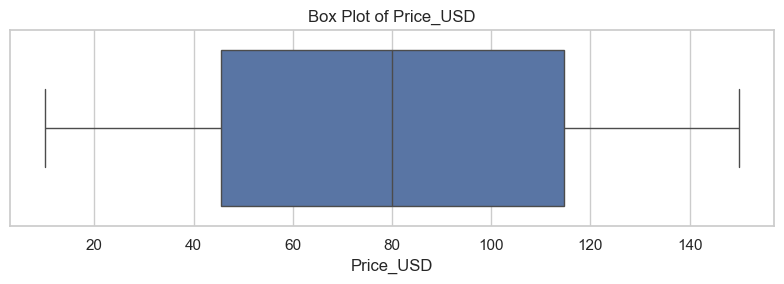

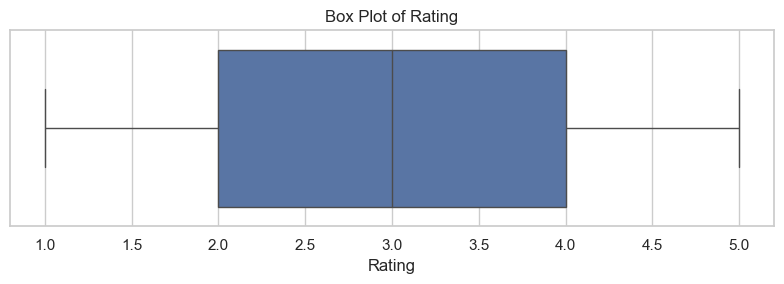

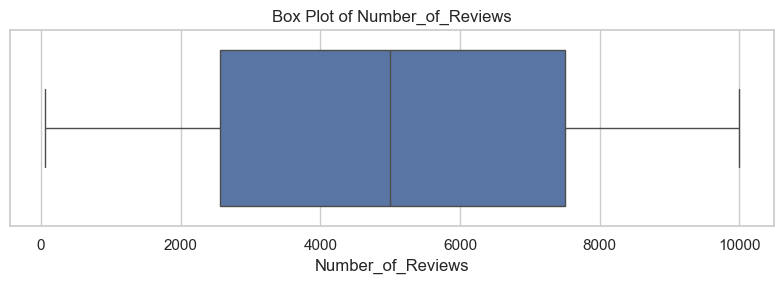

In [9]:
for col in numeric_columns[:8]:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Box Plot of {col}")
    plt.tight_layout()
    plt.show()


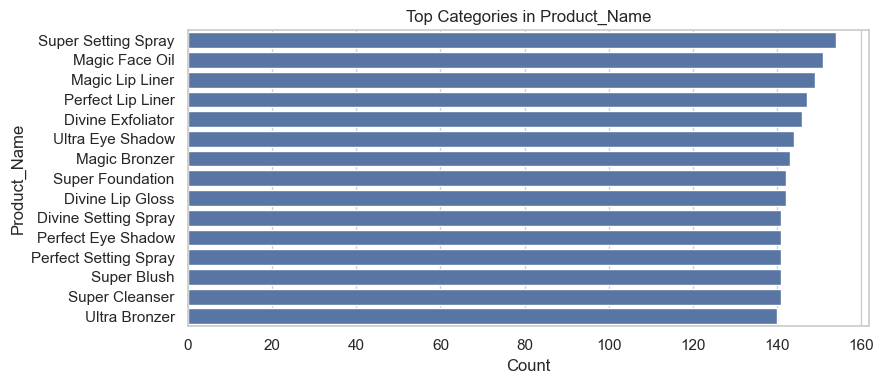

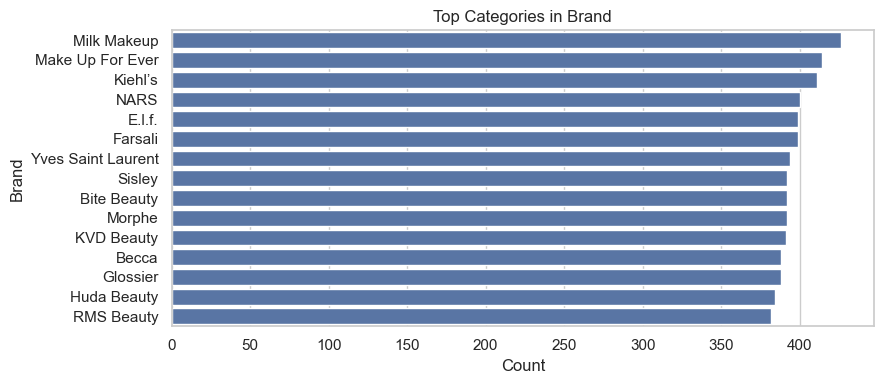

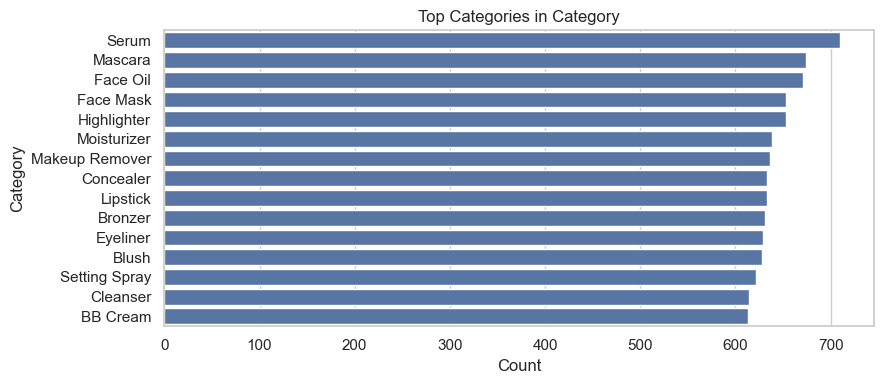

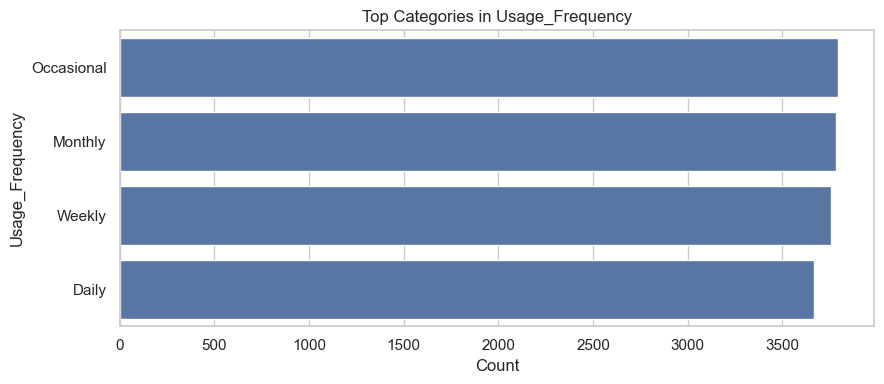

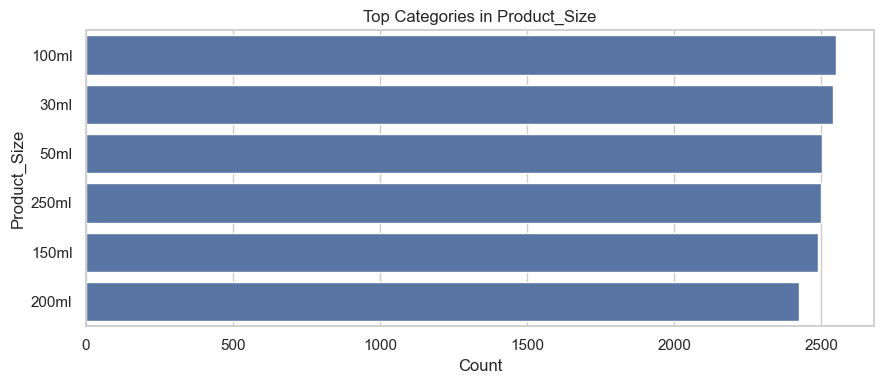

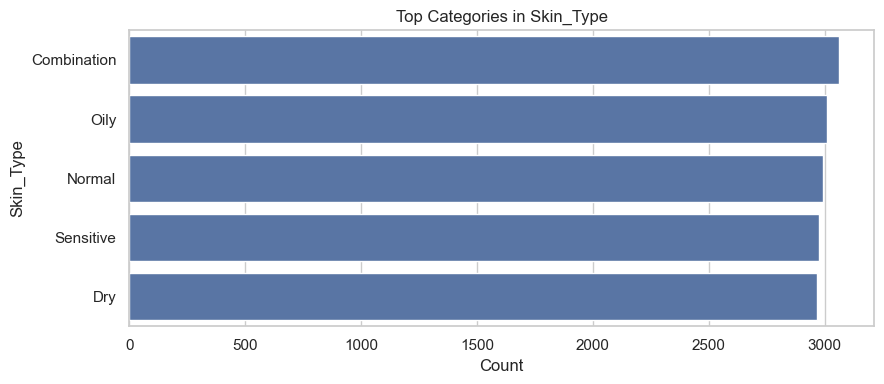

In [10]:
for col in categorical_columns[:6]:
    plt.figure(figsize=(9, 4))
    counts = df[col].value_counts().head(15)
    sns.barplot(x=counts.values, y=counts.index)
    plt.title(f"Top Categories in {col}")
    plt.xlabel("Count")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

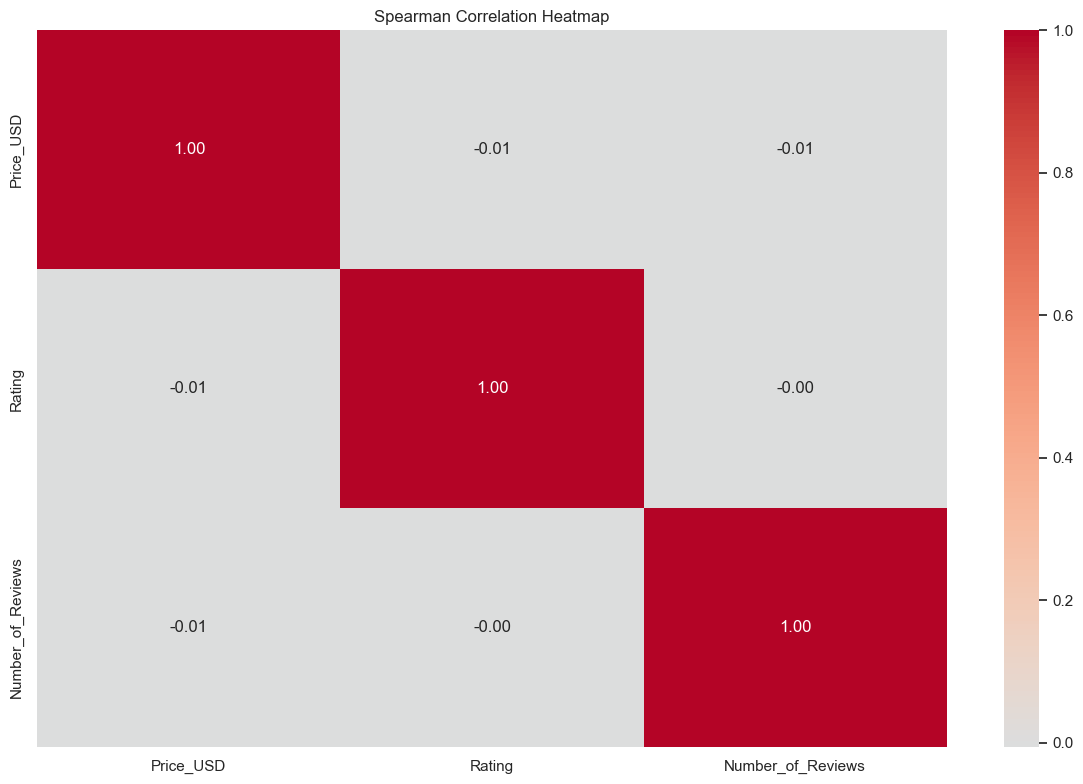

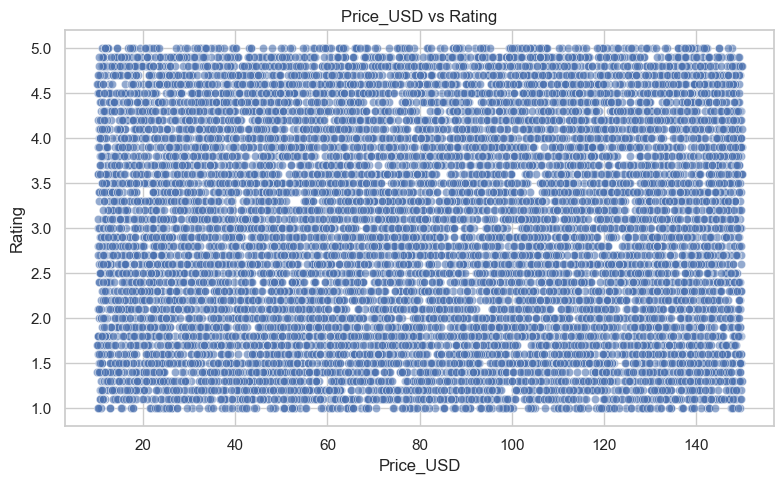

In [11]:

numeric_columns = df.select_dtypes(include=np.number).columns

if len(numeric_columns) >= 2: 
    correlation = df[numeric_columns].corr(method="spearman")

    plt.figure(figsize=(12, 8))
    sns.heatmap(
        correlation,
        annot=(len(correlation) <= 10),
        cmap="coolwarm",
        center=0,
        fmt=".2f"
    )
    plt.title("Spearman Correlation Heatmap")
    plt.tight_layout()
    plt.show()

    correlation.to_csv("outputs/correlation_matrix.csv") 
if len(numeric_columns) >= 2:
    x_col = numeric_columns[0]
    y_col = numeric_columns[1]

    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=df, x=x_col, y=y_col, alpha=0.6)
    plt.title(f"{x_col} vs {y_col}")
    plt.tight_layout()
    plt.show()

In [12]:
if len(numeric_columns) > 0 and len(categorical_columns) > 0:
    value_col = numeric_columns[0]
    group_col = categorical_columns[0]

    groups = [
        group[value_col].dropna().values
        for _, group in df.groupby(group_col, observed=True)
        if group[value_col].notna().sum() >= 2
    ]

    if len(groups) >= 2:
        try:
            result = stats.kruskal(*groups)

            print("\nKruskal-Wallis Test")
            print("Numerical variable:", value_col)
            print("Grouping variable:", group_col)
            print("Statistic:", result.statistic)
            print("P-value:", result.pvalue)

            if result.pvalue < 0.05:
                print(
                    "At least one group distribution differs "
                    "statistically; further investigation is needed."
                )
            else:
                print(
                    "Insufficient evidence of a group difference "
                    "at the 5% significance level."
                )
        except ValueError as error:
            print("Statistical test could not be completed:", error)


Kruskal-Wallis Test
Numerical variable: Price_USD
Grouping variable: Product_Name
Statistic: 110.97428871833513
P-value: 0.68755407001089
Insufficient evidence of a group difference at the 5% significance level.


In [13]:
date_columns = [
    col for col in df.columns
    if "date" in col.lower() or "time" in col.lower()
]

for date_col in date_columns:
    converted = pd.to_datetime(df[date_col], errors="coerce")

    if converted.notna().sum() > 0:
        df[date_col] = converted
        df[date_col + "_month"] = converted.dt.month
        df[date_col + "_dayofweek"] = converted.dt.dayofweek
        df[date_col + "_quarter"] = converted.dt.quarter

        monthly_counts = (
            converted.dropna()
            .dt.to_period("M")
            .value_counts()
            .sort_index()
        )

        plt.figure(figsize=(10, 4))
        monthly_counts.plot(kind="line", marker="o")
        plt.title(f"Monthly Record Trend: {date_col}")
        plt.xlabel("Month")
        plt.ylabel("Number of Records")
        plt.tight_layout()
        plt.show()

In [14]:
column_lookup = {col.lower(): col for col in df.columns}
 
def find_column(*possible_names):
    for name in possible_names:
        if name.lower() in column_lookup:
            return column_lookup[name.lower()]
    return None

customer_col = find_column("customer_id", "customerid", "client_id")
order_col = find_column("order_id", "orderid", "transaction_id")
product_col = find_column("product_id", "productid", "sku")
date_col = find_column("order_date", "purchase_date", "transaction_date", "date")
price_col = find_column("unit_price", "price", "selling_price")
quantity_col = find_column("quantity", "units", "quantity_sold")
discount_col = find_column("discount_rate", "discount", "discount_percentage")
category_col = find_column("category", "product_category")
rating_col = find_column("rating", "review_rating", "customer_rating")

if price_col and discount_col:
    price = pd.to_numeric(df[price_col], errors="coerce")
    discount = pd.to_numeric(df[discount_col], errors="coerce")
    discount_rate = discount.where(discount.between(0, 1))

    df["discount_rate_feature"] = discount_rate
    df["discounted_price_estimate"] = (
        price * (1 - discount_rate.fillna(0))
    )
if price_col and quantity_col:
    price = pd.to_numeric(df[price_col], errors="coerce")
    quantity = pd.to_numeric(df[quantity_col], errors="coerce")

    if "discount_rate_feature" in df.columns:
        df["estimated_revenue"] = (
            price * quantity *
            (1 - df["discount_rate_feature"].fillna(0))
        )
    else:
        df["estimated_revenue"] = price * quantity
 
if customer_col:
    aggregation = {}

    if order_col:
        aggregation[order_col] = "nunique"

    if "estimated_revenue" in df.columns:
        aggregation["estimated_revenue"] = ["sum", "mean"]

    if quantity_col:
        aggregation[quantity_col] = "sum"

    if rating_col:
        aggregation[rating_col] = "mean"

    if category_col:
        aggregation[category_col] = "nunique"

    if aggregation:
        customer_features = df.groupby(customer_col).agg(aggregation)
        customer_features.columns = [
            "_".join(str(part) for part in col if part)
            if isinstance(col, tuple) else str(col)
            for col in customer_features.columns
        ]
        customer_features = customer_features.reset_index()

        customer_features.to_csv(
            "outputs/customer_features.csv", index=False
        )
        print("\nCustomer features created:")
        print(customer_features.head())

if product_col:
    aggregation = {}

    if quantity_col:
        aggregation[quantity_col] = "sum"

    if "estimated_revenue" in df.columns:
        aggregation["estimated_revenue"] = "sum"

    if rating_col:
        aggregation[rating_col] = "mean"

    if order_col:
        aggregation[order_col] = "nunique"

    if aggregation:
        product_features = df.groupby(product_col).agg(aggregation)
        product_features.columns = [
            f"{col}_feature" for col in product_features.columns
        ]
        product_features = product_features.reset_index()

        product_features.to_csv(
            "outputs/product_features.csv", index=False
        )
        print("\nProduct features created:")
        print(product_features.head())


if category_col:
    aggregation = {}

    if quantity_col:
        aggregation[quantity_col] = "sum"

    if "estimated_revenue" in df.columns:
        aggregation["estimated_revenue"] = "sum"

    if rating_col:
        aggregation[rating_col] = "mean"

    if aggregation:
        category_performance = df.groupby(category_col).agg(aggregation)
        category_performance.to_csv(
            "outputs/category_performance.csv"
        )

        print("\nCategory performance:")
        print(category_performance.sort_values(
            by=list(aggregation.keys())[0],
            ascending=False
        ).head(10))

if customer_col and order_col and date_col and "estimated_revenue" in df.columns:
    valid = df.dropna(
        subset=[customer_col, order_col, date_col]
    ).copy()

    if not valid.empty:
        valid[date_col] = pd.to_datetime(valid[date_col], errors="coerce")
        valid = valid.dropna(subset=[date_col])

        if not valid.empty:
            order_level = (
                valid.groupby([customer_col, order_col, date_col], as_index=False)
                ["estimated_revenue"].sum()
            )

            cutoff = order_level[date_col].max() + pd.Timedelta(days=1)

            rfm = order_level.groupby(customer_col).agg(
                last_purchase=(date_col, "max"),
                frequency=(order_col, "nunique"),
                monetary=("estimated_revenue", "sum")
            ).reset_index()

            rfm["recency_days"] = (
                cutoff - rfm["last_purchase"]
            ).dt.days

            # Rank first to handle ties robustly in quantile binning.
            # Higher recency (more days inactive) should get a lower score.
            rfm["R_score"] = pd.qcut(
                rfm["recency_days"].rank(method="first", ascending=False),
                5, labels=False
            ) + 1

            rfm["F_score"] = pd.qcut(
                rfm["frequency"].rank(method="first"),
                5, labels=False
            ) + 1

            rfm["M_score"] = pd.qcut(
                rfm["monetary"].rank(method="first"),
                5, labels=False
            ) + 1

            rfm["RFM_score"] = (
                rfm["R_score"] + rfm["F_score"] + rfm["M_score"]
            )

            rfm.to_csv("outputs/customer_rfm.csv", index=False)

            print("\nRFM analysis:")
            print(rfm.head())


Category performance:
                 Rating
Category               
Contour        3.129305
Moisturizer    3.079467
CC Cream       3.073064
BB Cream       3.060359
Setting Spray  3.050161
Exfoliator     3.048542
Primer         3.035809
Highlighter    3.030168
Face Mask      3.015314
Foundation     3.008320


In [18]:
if len(categorical_columns) > 0:
    encoded_df = pd.get_dummies(
        df,
        columns=list(categorical_columns),
        drop_first=False,
        dtype=int
    )
    encoded_df.to_csv(
        "outputs/encoded_dataset.csv", index=False
    )
    print("\nEncoded dataset saved.")



Encoded dataset saved.


In [20]:
 if  len(numeric_columns) > 0:
    numeric_data = df[numeric_columns].replace(
        [np.inf, -np.inf], np.nan
    )

    # Median-fill only for this demonstration of scaling.
    numeric_data = numeric_data.fillna(numeric_data.median())

    standard_scaler = StandardScaler()
    standardized = pd.DataFrame(
        standard_scaler.fit_transform(numeric_data),
        columns=numeric_columns
    )
    standardized.to_csv(
        "outputs/standardized_numeric_features.csv", index=False
    )

    minmax_scaler = MinMaxScaler()
    normalized = pd.DataFrame(
        minmax_scaler.fit_transform(numeric_data),
        columns=numeric_columns
    )
    normalized.to_csv(
        "outputs/normalized_numeric_features.csv", index=False
    )


In [21]:
df.to_csv("outputs/eda_feature_engineered_dataset.csv", index=False)

print("\n" + "=" * 60)
print("EDA AND FEATURE ENGINEERING COMPLETED")
print("=" * 60)
print("Original/processed dataset shape:", df.shape)
print("Results saved in the 'outputs' folder.")
print("Review the data-quality report before interpreting results.")
print("All sales values are estimates; validate prices, discounts,")
print("returns, taxes, and currency definitions against your dataset.")


EDA AND FEATURE ENGINEERING COMPLETED
Original/processed dataset shape: (15000, 14)
Results saved in the 'outputs' folder.
Review the data-quality report before interpreting results.
All sales values are estimates; validate prices, discounts,
returns, taxes, and currency definitions against your dataset.
